# Khảo sát dataset gốc: phân bổ và chất lượng nhãn `domain`

Dataset: **VTSNLP/vietnamese_curated_dataset** · Seed: **42** · Mẫu khảo sát: **300.000 bài**.

Báo cáo trình bày kết quả đã chạy, với bảng tổng hợp và biểu đồ đặt ngay trong từng mục.
Nhãn gốc do `nvidia/domain-classifier` gán, chưa được người kiểm duyệt.
Các phép đo dưới đây cung cấp bằng chứng cho việc xem xét nhãn; chưa kết luận giữ, gộp hay bỏ nhãn.

**Phạm vi của ba tập số liệu**

| Tập số liệu | Số bài | Dùng để làm gì? |
|---|---:|---|
| Toàn bộ dataset gốc | 12.169.131 | Đếm nhãn và khảo sát phân bổ theo file |
| Mẫu khảo sát | 300.000 | Khảo sát độ dài, đặc trưng từ vựng, trùng lặp và tạo tập phân tích |
| Tập phân tích | 95.753 | Đánh giá mô hình out-of-fold, đo độ lẫn và nghi vấn gán sai; tối đa 4.000 bài/nhãn |

Mẫu **Bronze 50.000 bài** là tập riêng được dùng để so sánh phân bổ; các ID Bronze đã được loại khỏi mẫu khảo sát.

**Mục lục:** [Tóm tắt](#tom-tat) · [Phân bổ và lấy mẫu](#phan-bo) · [Hồ sơ nhãn](#ho-so) · [Độ lẫn và F1](#do-lan) · [Nghi vấn gán sai](#nghi-van) · [Kịch bản](#kich-ban) · [Giới hạn](#gioi-han) · [Thông tin lần chạy](#lan-chay).

<a id="tom-tat"></a>

## 1. Các kết quả chính

1. Toàn bộ dataset có **12,169,131** bài trong **132** file, **12,276** row group.
2. Có **25** giá trị nhãn khác nhau; nhãn không nằm trong `domains_v1.yaml` (kể cả null/rỗng/`Adult`): **không có**.
3. Nhãn lớn nhất / nhỏ nhất (trong các nhãn chuẩn có mặt) = **18.0** lần (Arts_and_Entertainment / Online_Communities).
4. Mẫu Bronze 50k lệch so với toàn bộ: TVD = **0.0129**, chênh lớn nhất **0.32** điểm %.
5. Mẫu khảo sát ngẫu nhiên: **300,000** bài; so với toàn bộ TVD = **0.0065**.
6. Mô hình phân tích out-of-fold: Macro-F1 = **0.786**, accuracy = **0.793** (trên 95,753 bài, mỗi nhãn tối đa 4,000).
7. Cặp lẫn nhiều nhất: **Law_and_Government ↔ News** (sym_confusion = 0.077).
8. Nhãn có F1 thấp nhất: **Online_Communities** (F1 = 0.575).
9. Nhãn có tỉ lệ nghi gán sai cao nhất: **News** (6.8% bài bị đoán thành nhãn khác với xác suất ≥ 0.7).
10. Nhóm bài giống hệt nhau nhưng khác nhãn: **0** nhóm (0 bài) trong mẫu khảo sát.
11. Chỉ đọc 1000 ký tự đầu: Macro-F1 = **0.783** so với **0.786** khi đọc tới 5000 ký tự.

<a id="phan-bo"></a>

## 2. Phân bổ dataset và mức độ đại diện của mẫu

### 2.1. Phân bổ của toàn bộ 12,17 triệu bài

Nhãn lớn nhất chiếm **7,73%**, nhãn nhỏ nhất chiếm **0,43%**; số bài chênh nhau khoảng **18 lần**.
Không phát hiện nhãn ngoài danh sách chuẩn, nhãn rỗng/null hay `Adult` trong lần quét này.

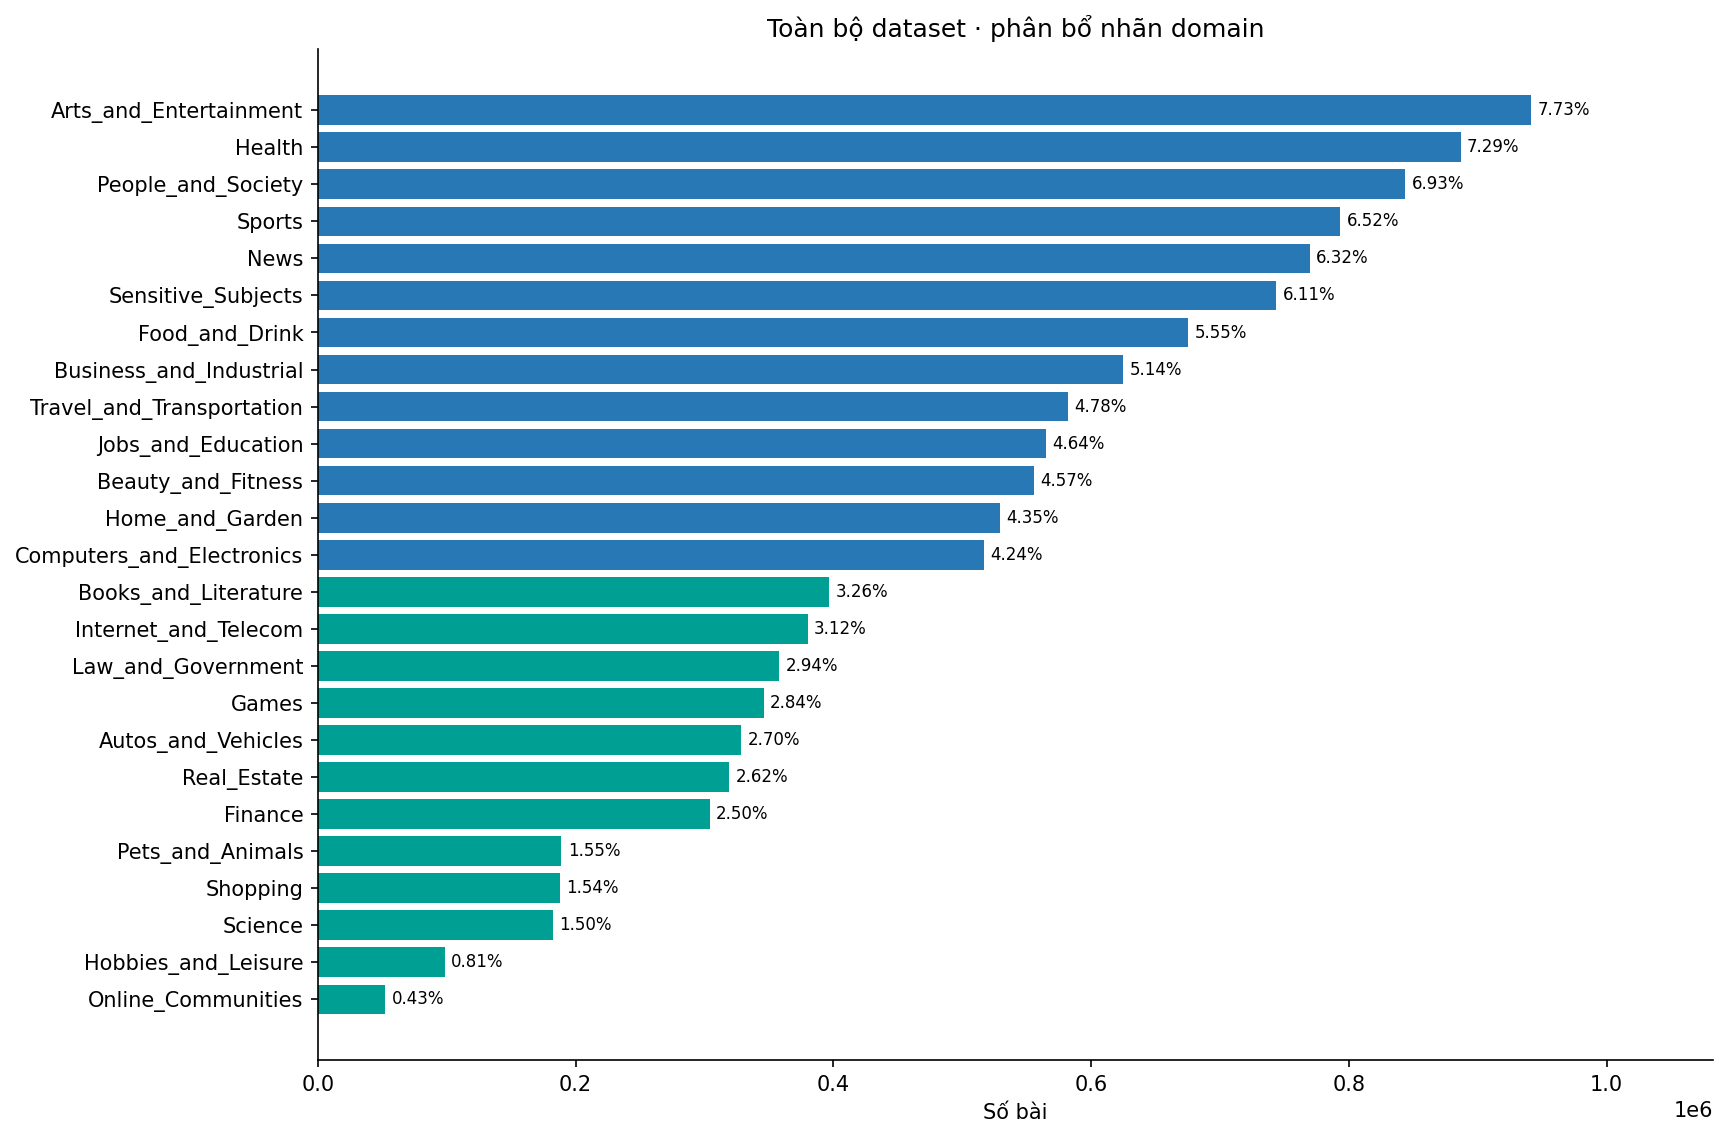

*Hình 1. Phân bổ trên toàn bộ dataset, sắp theo số bài giảm dần. Đây là tỉ lệ nguồn, trước khi giới hạn số bài mỗi nhãn trong tập phân tích.*

| label | count | pct | rank | kind |
|---|---|---|---|---|
| Arts_and_Entertainment | 941,159 | 7.73 | 1 | known |
| Health | 886,657 | 7.29 | 2 | known |
| People_and_Society | 843,624 | 6.93 | 3 | known |
| Sports | 793,235 | 6.52 | 4 | known |
| News | 769,510 | 6.32 | 5 | known |
| Sensitive_Subjects | 743,582 | 6.11 | 6 | known |
| Food_and_Drink | 675,447 | 5.55 | 7 | known |
| Business_and_Industrial | 624,991 | 5.14 | 8 | known |
| Travel_and_Transportation | 581,803 | 4.78 | 9 | known |
| Jobs_and_Education | 564,654 | 4.64 | 10 | known |
| Beauty_and_Fitness | 555,714 | 4.57 | 11 | known |
| Home_and_Garden | 529,616 | 4.35 | 12 | known |
| Computers_and_Electronics | 516,543 | 4.24 | 13 | known |
| Books_and_Literature | 396,770 | 3.26 | 14 | known |
| Internet_and_Telecom | 379,943 | 3.12 | 15 | known |
| Law_and_Government | 358,097 | 2.94 | 16 | known |
| Games | 345,954 | 2.84 | 17 | known |
| Autos_and_Vehicles | 328,610 | 2.70 | 18 | known |
| Real_Estate | 319,040 | 2.62 | 19 | known |
| Finance | 304,233 | 2.50 | 20 | known |
| Pets_and_Animals | 189,001 | 1.55 | 21 | known |
| Shopping | 187,516 | 1.54 | 22 | known |
| Science | 182,682 | 1.50 | 23 | known |
| Hobbies_and_Leisure | 98,387 | 0.81 | 24 | known |
| Online_Communities | 52,363 | 0.43 | 25 | known |

### 2.2. Phân bổ theo vị trí file

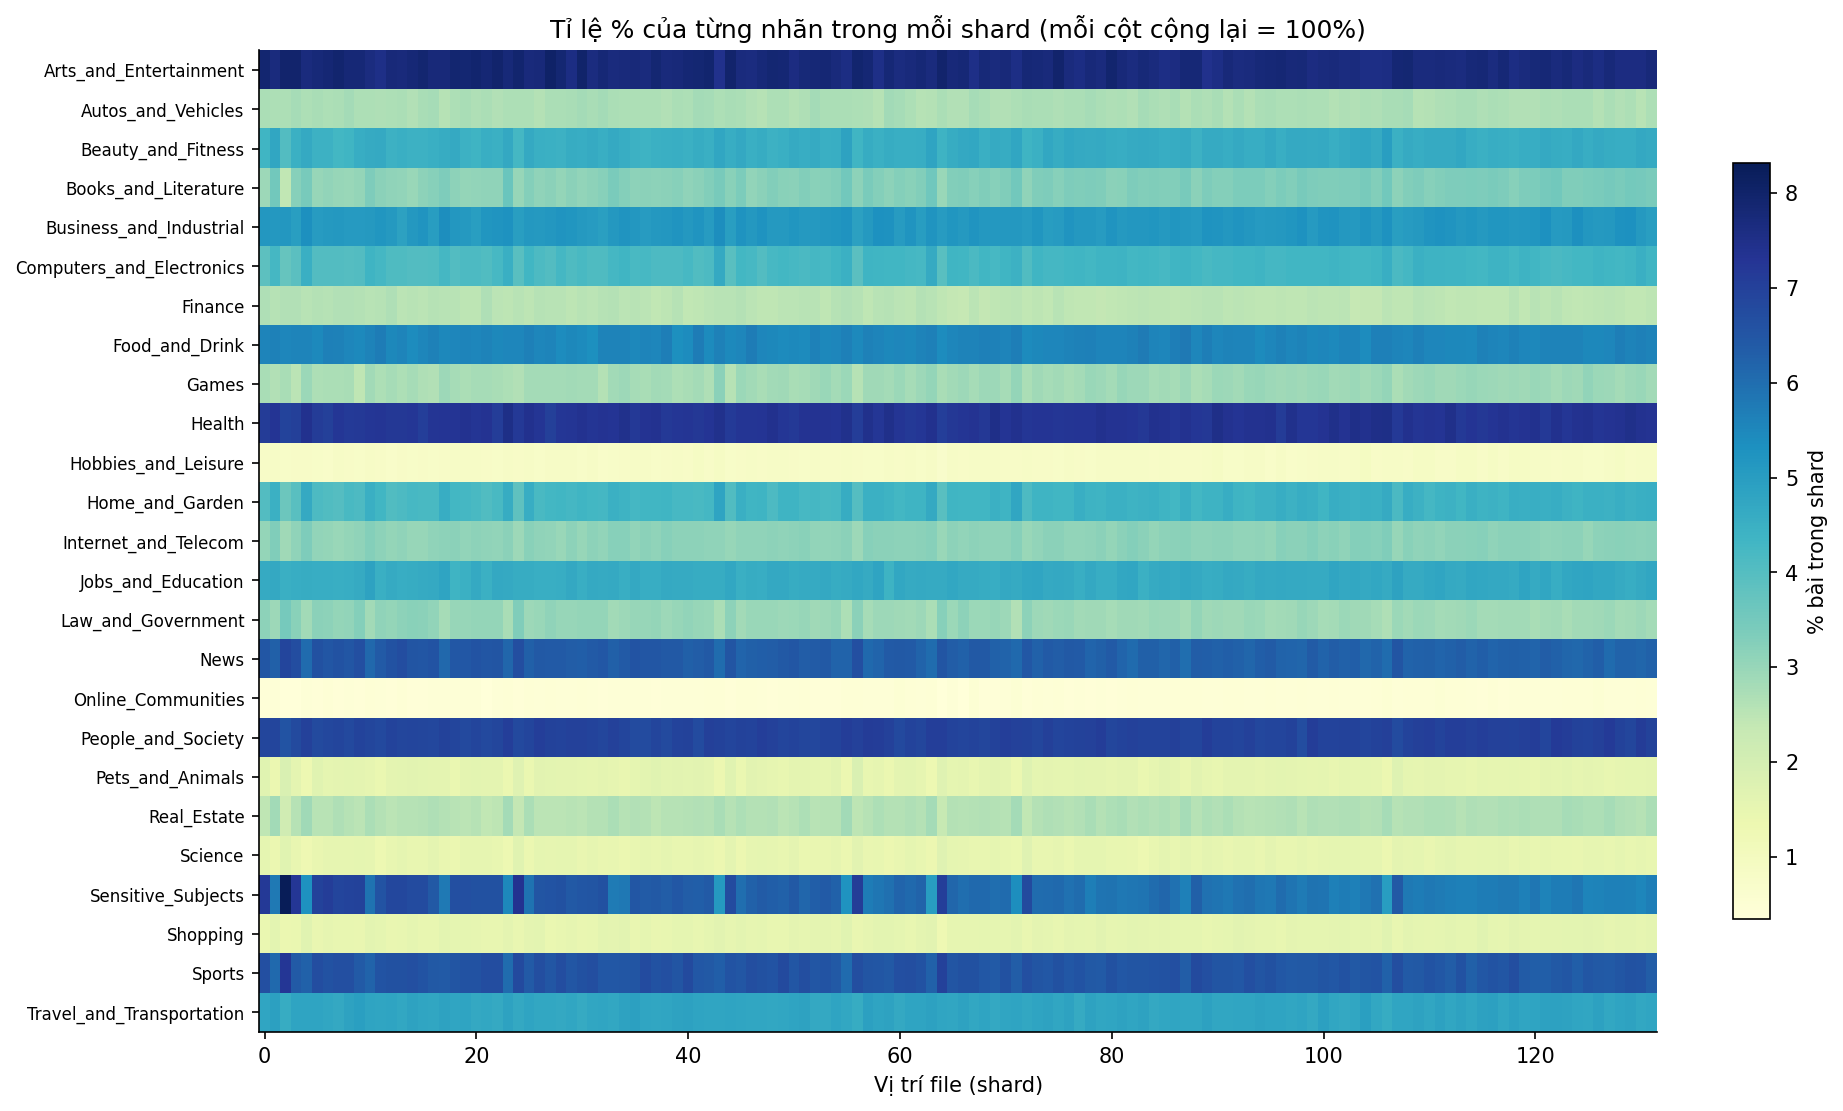

*Hình 2. Mỗi cột là một file (shard), mỗi hàng là một nhãn; màu biểu thị % bài của nhãn trong file. Tổng mỗi cột bằng 100%.*

**Năm nhãn dao động nhiều nhất giữa các file**; độ lệch chuẩn tính theo điểm phần trăm.

| label | pct_min | pct_max | pct_std | corr_with_file_index |
|---|---|---|---|---|
| Sensitive_Subjects | 5.00 | 8.31 | 0.51 | -0.65 |
| Home_and_Garden | 3.62 | 4.81 | 0.18 | 0.51 |
| News | 6.01 | 6.89 | 0.16 | -0.55 |
| Books_and_Literature | 2.42 | 3.67 | 0.16 | 0.56 |
| Sports | 6.04 | 7.23 | 0.16 | -0.20 |

### 2.3. Mẫu Bronze 50k và các snapshot

Bronze 50k có **TVD = 0,0129**, chênh lệch lớn nhất **0,32 điểm phần trăm** so với toàn bộ dataset. TVD = ½ × tổng chênh lệch tuyệt đối giữa hai phân phối tỉ lệ; TVD = 0 nghĩa là hai phân phối trùng nhau. Phép so sánh này chỉ đo cơ cấu nhãn.

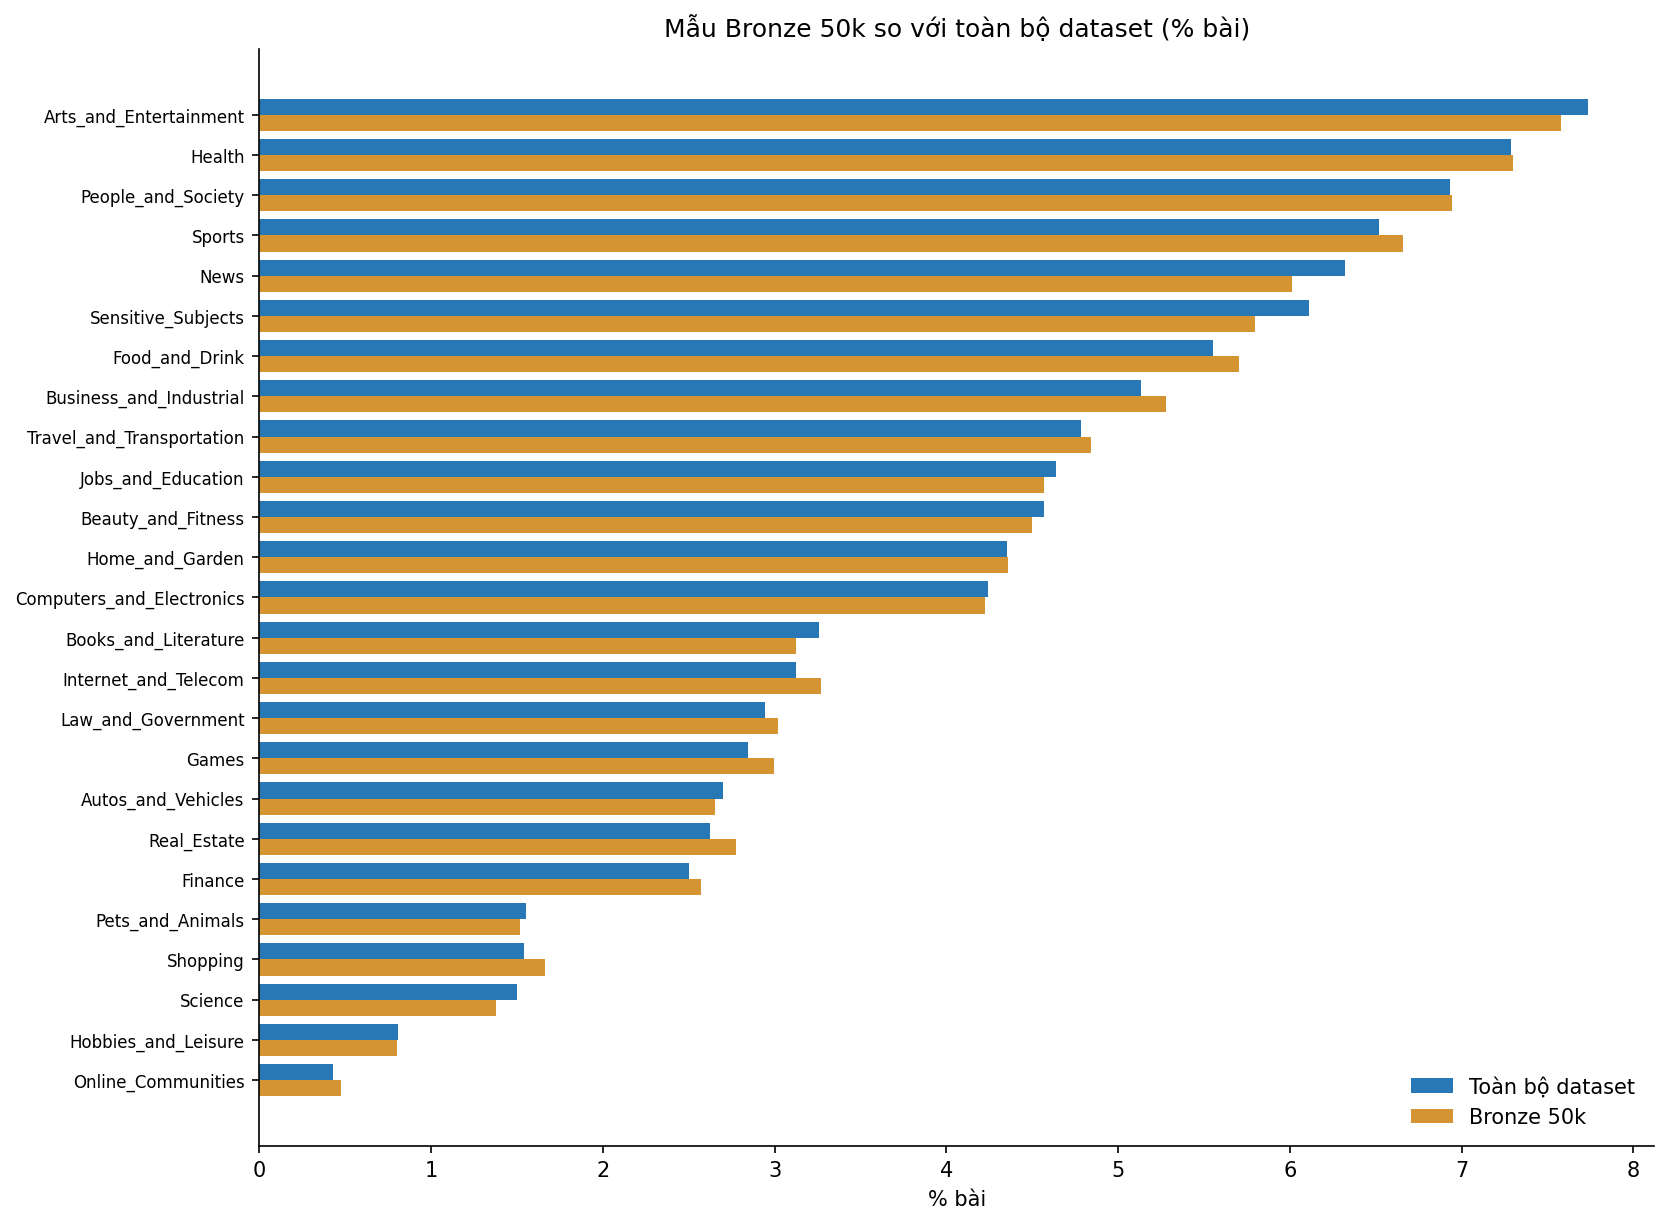

*Hình 3. Hai cột cạnh nhau biểu thị tỉ lệ nhãn trong nguồn và Bronze 50k. Nhìn độ chênh theo điểm phần trăm cùng TVD để đánh giá mức lệch.*

**Kiểm định chi-square:** χ² = 54,3; p = 0,000386. Với cỡ mẫu lớn, p nhỏ có thể đi cùng chênh lệch thực tế nhỏ; cần đọc cùng độ lớn chênh lệch.

**Mười nhãn chênh nhiều nhất:**

| label | reference_pct | other_pct | diff_pct_points | ratio |
|---|---|---|---|---|
| Sensitive_Subjects | 6.11 | 5.79 | -0.32 | 0.95 |
| News | 6.32 | 6.01 | -0.31 | 0.95 |
| Arts_and_Entertainment | 7.73 | 7.58 | -0.16 | 0.98 |
| Real_Estate | 2.62 | 2.77 | +0.15 | 1.06 |
| Food_and_Drink | 5.55 | 5.70 | +0.15 | 1.03 |
| Games | 2.84 | 2.99 | +0.15 | 1.05 |
| Internet_and_Telecom | 3.12 | 3.27 | +0.15 | 1.05 |
| Business_and_Industrial | 5.14 | 5.28 | +0.14 | 1.03 |
| Sports | 6.52 | 6.66 | +0.14 | 1.02 |
| Books_and_Literature | 3.26 | 3.13 | -0.13 | 0.96 |

**Các snapshot Silver và Gold train so với nguồn:**

| snapshot | rows | total_variation_distance | max_abs_gap_pct_points | note |
|---|---|---|---|---|
| silver: silver_quality_v1_b81fcce589_seed42_buf10000_n50000 | 50000 | 0.0129 | 0.32 |  |
| silver: silver_quality_v2_8cadceaf8fd0_a6f9d7727f | 49998 | 0.0129 | 0.32 |  |
| gold train: gold_manifest_v1_8cadceaf8fd0_cf811f9b2c | 39986 | 0.0129 | 0.32 |  |
| gold train: gold_manifest_v2_9bef360a5f6d_d7b098c4e6 | 39985 | 0.0129 | 0.32 |  |

### 2.4. Mẫu khảo sát 300k

Mẫu khảo sát có **TVD = 0,0065** và chênh lệch lớn nhất **0,34 điểm phần trăm** so với nguồn. TVD thấp hơn Bronze trong lần chạy này chỉ cho biết phân bổ nhãn gần nguồn hơn theo thước đo đó.

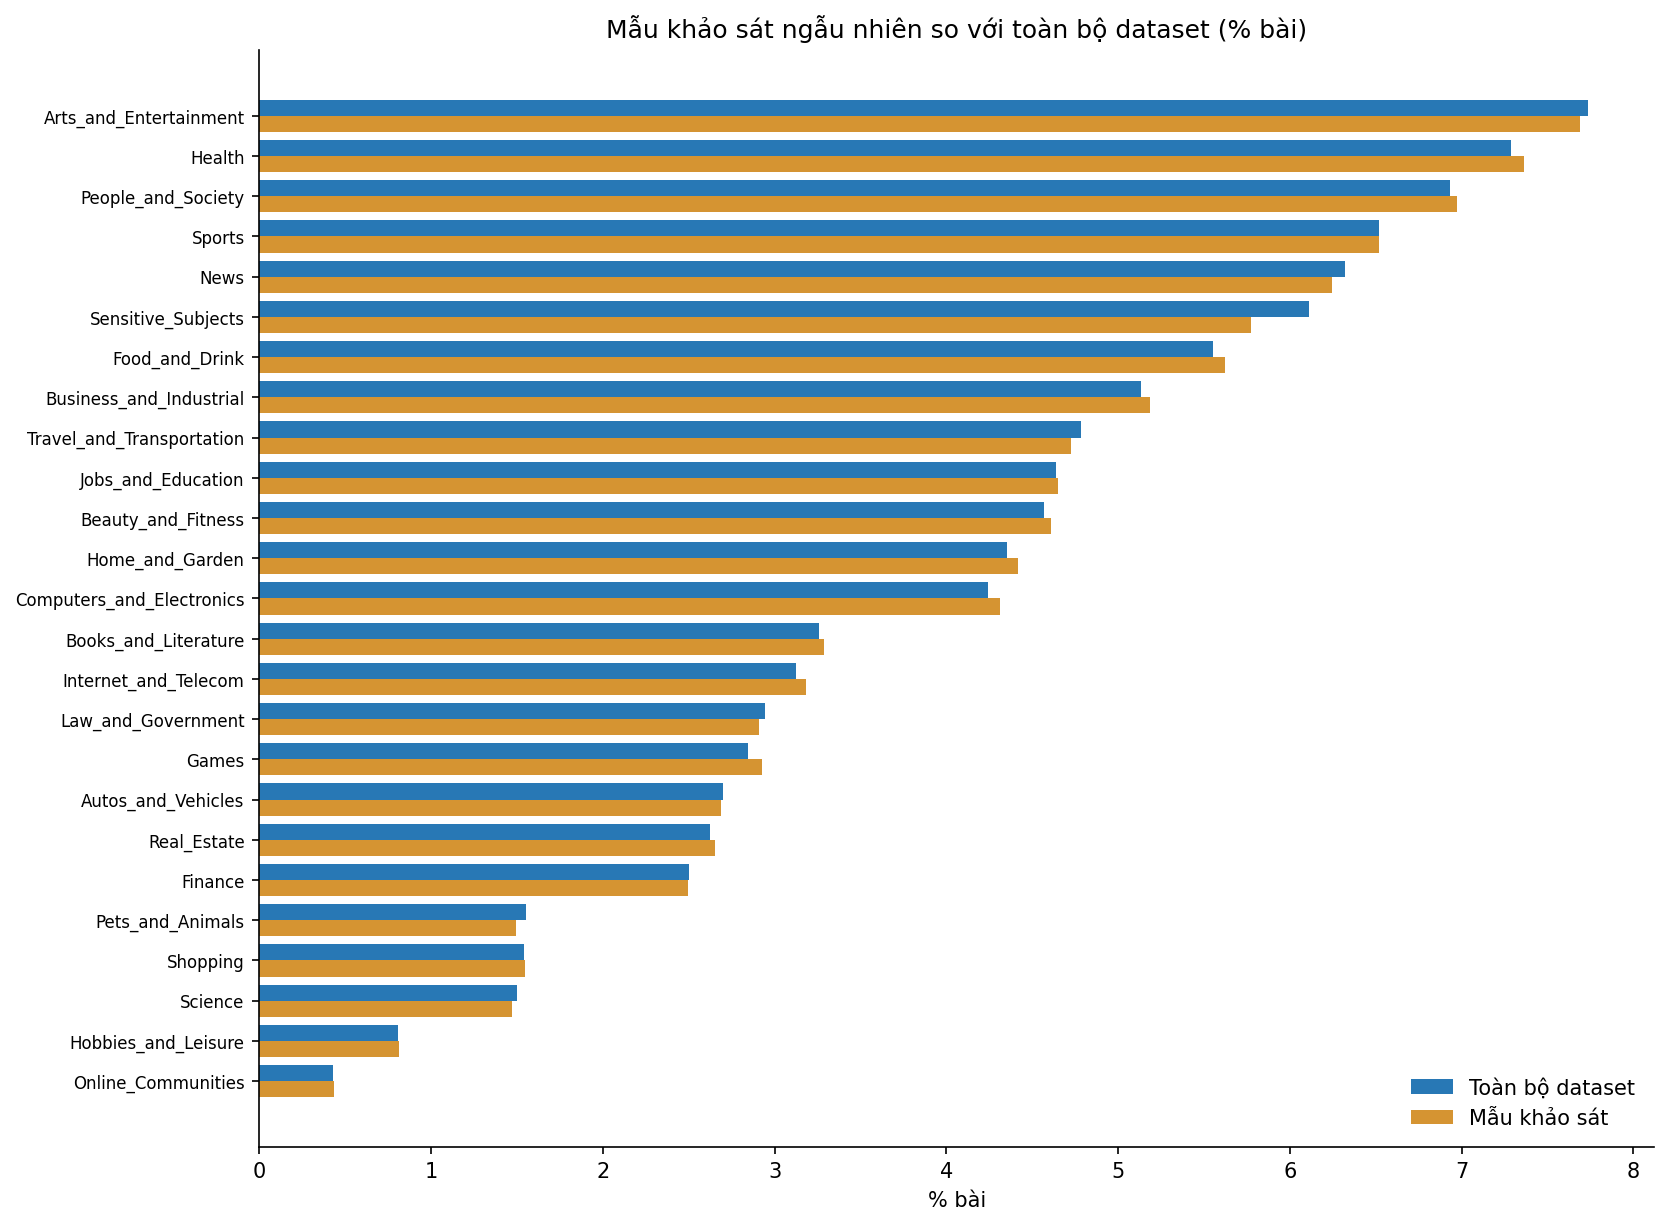

*Hình 4. Phân bổ của mẫu khảo sát sau khi loại ID Bronze, đối chiếu với phân bổ toàn bộ dataset.*

| Tham số lấy mẫu | Giá trị |
|---|---|
| Phương pháp | Chọn ngẫu nhiên row group trên toàn bộ các file, rồi lấy ngẫu nhiên dòng trong từng row group |
| Seed | 42 |
| Số file được lấy mẫu | 132 |
| Số row group dự kiến chọn / tổng số | 1.395 / 12.276 |
| Số dòng dự kiến giữ trong mỗi row group | 222 |
| Số dòng đọc từ các row group | 309.122 |
| Số bài loại vì trùng ID Bronze | 1.384 |
| Số bài cuối cùng | 300.000 |
| Ngân sách tải cấu hình | 4,0 GB |

Số dòng đọc là số trung gian trước khi loại ID Bronze và giới hạn về 300.000 bài.
Lấy mẫu theo row group cần được đọc cùng giới hạn về tính tương đồng giữa các bài trong một group ở mục 7.

<a id="ho-so"></a>

## 3. Hồ sơ độ dài và từ vựng của nhãn

### 3.1. Độ dài bài viết

Trên mẫu 300k, trung vị là **607 tiếng**; **83,88%** bài dài hơn 256 tiếng và **58,31%** dài hơn 512 tiếng.
Các ngưỡng theo tiếng chỉ mô tả văn bản, không quy đổi trực tiếp sang giới hạn token của mô hình gán nhãn.

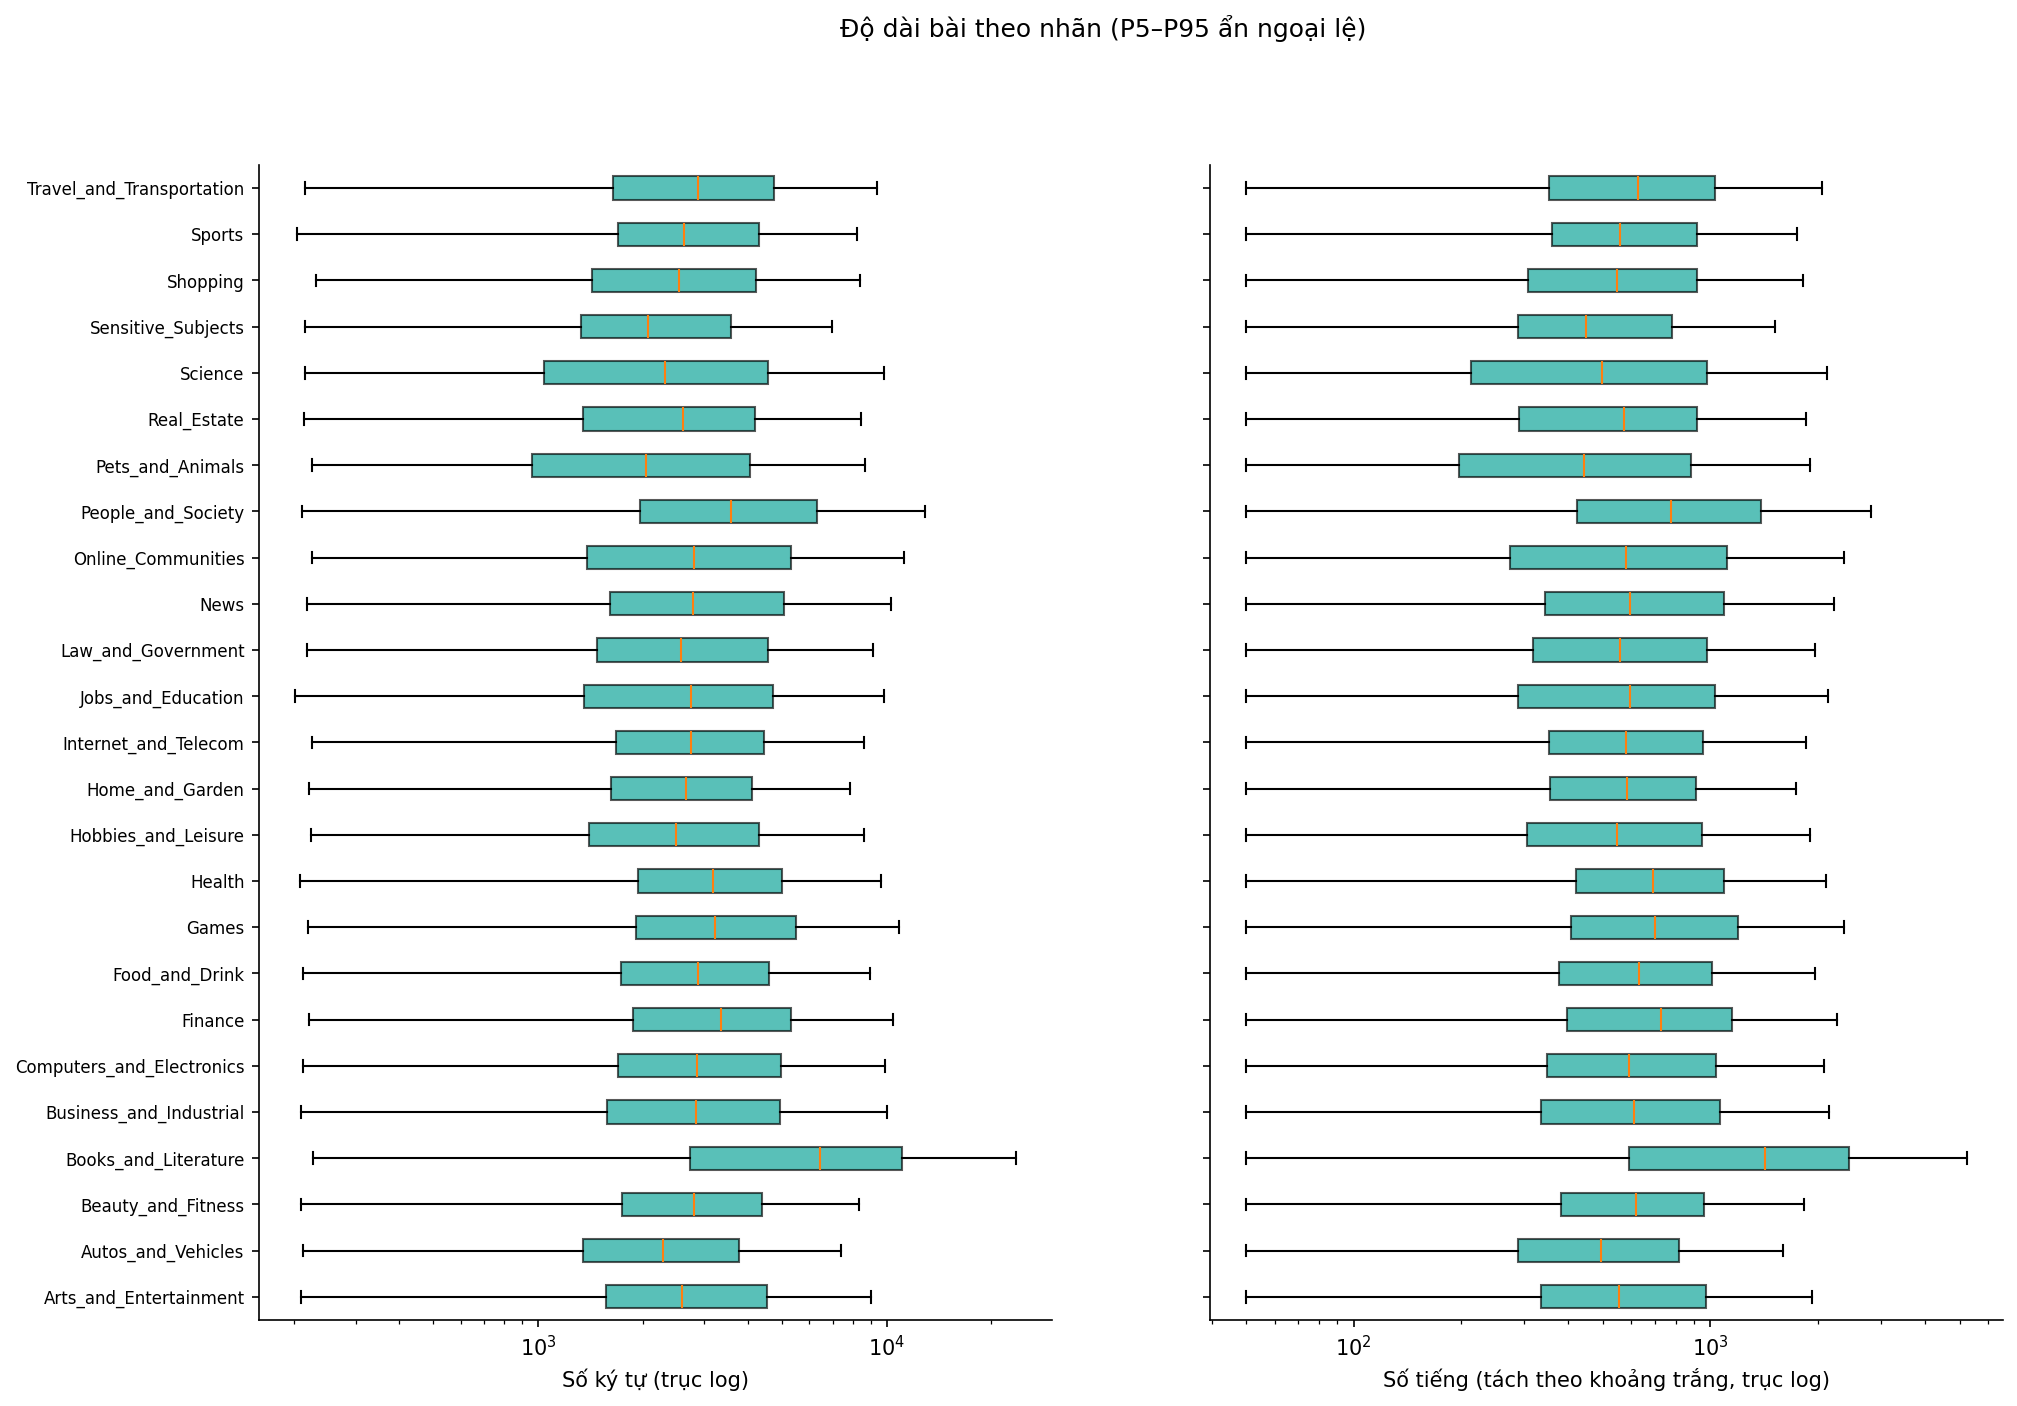

*Hình 5. Hai biểu đồ hộp dùng trục log để so sánh độ dài ký tự và tiếng. Đường trong hộp là trung vị; các điểm ngoại lệ được ẩn. Bảng dưới cung cấp các phân vị cụ thể.*

| label | n | chars_p50 | tieng_p5 | tieng_p50 | tieng_p95 | share_gt_256_tieng | share_gt_512_tieng |
|---|---|---|---|---|---|---|---|
| Arts_and_Entertainment | 23066 | 2,596 | 121 | 554 | 2,148 | 0.84 | 0.54 |
| Autos_and_Vehicles | 8072 | 2,284 | 109 | 492 | 1,708 | 0.79 | 0.48 |
| Beauty_and_Fitness | 13821 | 2,806 | 136 | 617 | 2,051 | 0.86 | 0.61 |
| Books_and_Literature | 9868 | 6,432 | 154 | 1,421 | 5,876 | 0.89 | 0.78 |
| Business_and_Industrial | 15564 | 2,841 | 109 | 611 | 2,286 | 0.82 | 0.58 |
| Computers_and_Electronics | 12937 | 2,854 | 133 | 592 | 2,451 | 0.85 | 0.57 |
| Finance | 7490 | 3,353 | 122 | 725 | 2,099 | 0.86 | 0.66 |
| Food_and_Drink | 16860 | 2,870 | 125 | 630 | 2,131 | 0.86 | 0.61 |
| Games | 8777 | 3,216 | 159 | 698 | 2,473 | 0.89 | 0.65 |
| Health | 22086 | 3,180 | 140 | 692 | 2,264 | 0.88 | 0.67 |
| Hobbies_and_Leisure | 2440 | 2,487 | 105 | 546 | 2,130 | 0.80 | 0.54 |
| Home_and_Garden | 13248 | 2,660 | 132 | 585 | 1,874 | 0.85 | 0.58 |
| Internet_and_Telecom | 9556 | 2,746 | 126 | 581 | 2,056 | 0.85 | 0.57 |
| Jobs_and_Education | 13951 | 2,744 | 71 | 595 | 2,284 | 0.77 | 0.56 |
| Law_and_Government | 8724 | 2,575 | 98 | 557 | 2,165 | 0.82 | 0.54 |
| News | 18734 | 2,782 | 111 | 595 | 2,613 | 0.84 | 0.57 |
| Online_Communities | 1313 | 2,796 | 87 | 578 | 2,842 | 0.77 | 0.55 |
| People_and_Society | 20924 | 3,569 | 123 | 777 | 4,229 | 0.87 | 0.68 |
| Pets_and_Animals | 4491 | 2,045 | 62 | 443 | 2,186 | 0.69 | 0.44 |
| Real_Estate | 7960 | 2,606 | 108 | 574 | 1,710 | 0.79 | 0.55 |
| Science | 4422 | 2,317 | 51 | 496 | 2,689 | 0.71 | 0.49 |
| Sensitive_Subjects | 17318 | 2,066 | 129 | 449 | 1,939 | 0.81 | 0.43 |
| Shopping | 4648 | 2,529 | 100 | 546 | 1,859 | 0.80 | 0.53 |
| Sports | 19551 | 2,625 | 126 | 559 | 1,593 | 0.87 | 0.55 |
| Travel_and_Transportation | 14179 | 2,884 | 120 | 626 | 2,241 | 0.84 | 0.60 |

Ghi chú: *tiếng* được đếm bằng cách tách theo khoảng trắng, không phải token của mô hình.
`p5`, `p50`, `p95` lần lượt là phân vị 5%, trung vị và phân vị 95%.
Các cột `share_gt_*` là tỉ lệ từ 0 đến 1: ví dụ 0,54 tương ứng 54%.

### 3.2. Từ và cụm từ đặc trưng

Sáu từ/cụm từ có trọng số đặc trưng cao nhất của mỗi nhãn được trình bày trực tiếp bên dưới.

| label | 6 từ/cụm đặc trưng nhất |
|---|---|
| Arts_and_Entertainment | phim, nhạc, diễn viên, bộ phim, hát, khán giả |
| Autos_and_Vehicles | xe, toyota, mẫu xe, honda, động cơ, chiếc xe |
| Beauty_and_Fitness | da, tóc, mụn, làn da, kem, hoa hậu |
| Books_and_Literature | hắn, ngươi, truyện, nàng, chap, thơ |
| Business_and_Industrial | doanh, doanh nghiệp, máy nghiền, nghiền, nghiệp, kế toán |
| Computers_and_Electronics | loa, laptop, windows, máy tính, usb, máy in |
| Finance | giao dịch, ngân hàng, bitcoin, vay, ngân, giá vàng |
| Food_and_Drink | món, ngon, thịt, món ăn, bánh, ăn |
| Games | game, chơi, người chơi, cược, trò chơi, nhà cái |
| Health | bệnh, thuốc, viêm, điều trị, bệnh nhân, răng |
| Hobbies_and_Leisure | cưới, ảnh cưới, gốm, noel, giáng sinh, tết |
| Home_and_Garden | bếp, gỗ, sofa, nội thất, tủ, giặt |
| Internet_and_Telecom | iphone, sim, galaxy, smartphone, điện thoại, samsung |
| Jobs_and_Education | học, học sinh, du học, giáo dục, giáo, sinh viên |
| Law_and_Government | luật, công an, pháp luật, luật sư, bị cáo, tội |
| News | đảng, trump, tổng thống, ông trump, bầu cử, cử |
| Online_Communities | chatroulette, facebook, chat, tiktok, nặc danh, tik tok |
| People_and_Society | phật, chúa, thánh, ngài, thiên chúa, giêsu |
| Pets_and_Animals | loài, chó, động vật, mèo, chim, một loài |
| Real_Estate | căn hộ, dự án, căn, bất động, chung cư, động sản |
| Science | hành tinh, tiểu hành, khoa học, trái đất, đai chính, tinh vành |
| Sensitive_Subjects | nạn, syria, nạn nhân, hiện trường, ma túy, tên lửa |
| Shopping | đồng hồ, giày, thời trang, shop, áo, chiếc đồng |
| Sports | trận, bóng, cầu thủ, bóng đá, hlv, đấu |
| Travel_and_Transportation | du lịch, du, du khách, sạn, khách sạn, lịch |

<a id="do-lan"></a>

## 4. Mô hình phân tích: độ lẫn và hiệu năng theo nhãn

### 4.1. Thiết lập và kết quả tổng thể

TF-IDF + Logistic Regression được dùng như một công cụ khảo sát trên **95.753 bài**, tối đa **4.000 bài/nhãn**.
Bộ phân loại được đánh giá bằng **5-fold stratified out-of-fold**: bài được dự đoán trong fold mà bộ phân loại chưa dùng để huấn luyện.
Tuy nhiên, TF-IDF được fit một lần trên toàn tập phân tích, nên từ vựng và IDF có sử dụng văn bản của các fold đánh giá; xem giới hạn ở mục 7.

| Chỉ số | Giá trị |
|---|---:|
| Macro-F1 | 0,7857 |
| Accuracy | 0,7929 |
| Weighted-F1 | 0,7932 |
| Số nhãn | 25 |
| Số đặc trưng TF-IDF | 100.000 |
| Giới hạn đầu vào | 5.000 ký tự/bài |

Các chỉ số này thuộc tập phân tích đã giới hạn số bài mỗi nhãn và quy trình khảo sát trên;
không so trực tiếp với kết quả baseline Gold hay diễn giải thành chất lượng trên toàn bộ nguồn.

### 4.2. Ma trận lẫn out-of-fold

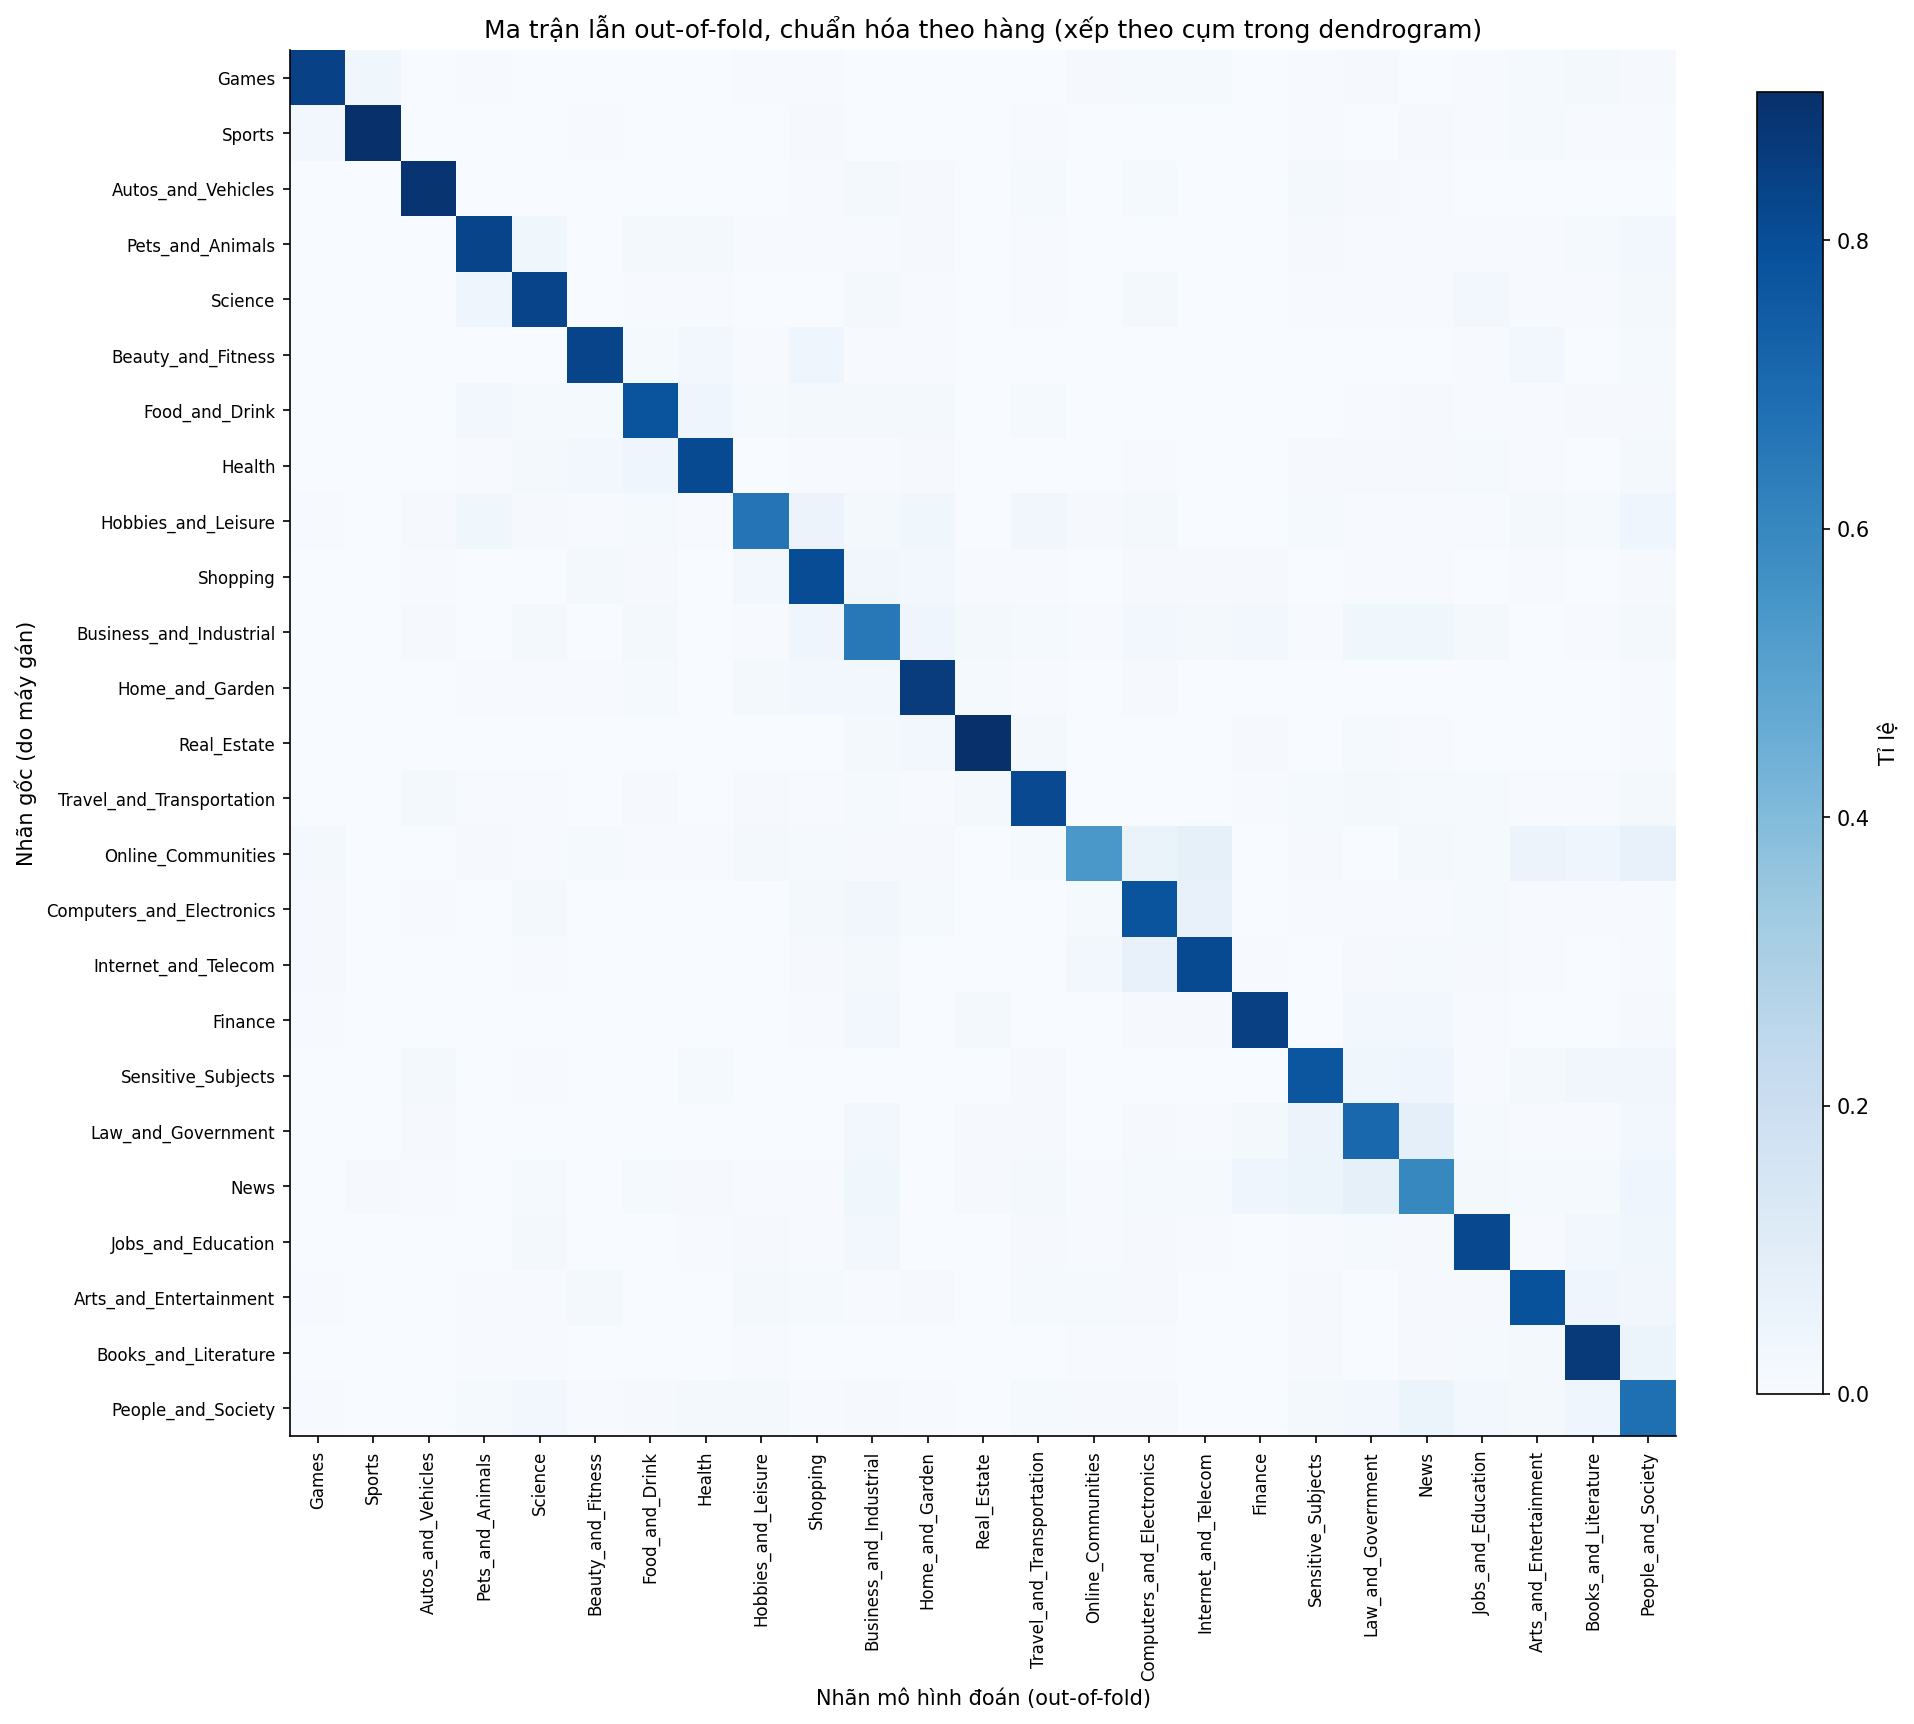

*Hình 6. Hàng là nhãn nguồn do máy gán, cột là nhãn mô hình khảo sát dự đoán. Mỗi hàng có tổng bằng 1; đường chéo là tỉ lệ dự đoán trùng nhãn nguồn. Các nhãn được xếp theo cây gom nhóm.*

### 4.3. Những cặp nhãn dễ lẫn

Ba tín hiệu được tính từ dự đoán và đặc trưng của cùng mô hình phân tích:

| Tín hiệu | Cách đọc |
|---|---|
| `sym_confusion` | Trung bình của hai tỉ lệ dự đoán nhầm A → B và B → A trên ma trận chuẩn hóa theo hàng |
| `top2_ambiguity` | Tỉ lệ bài thuộc A/B có hai dự đoán đầu là A/B và chênh xác suất nhỏ hơn 0,2 |
| `centroid_cosine` | Độ tương đồng cosine giữa vector TF-IDF trung bình của hai nhãn |

Đây là các góc đo bổ sung; không giả định chúng độc lập về mặt thống kê.

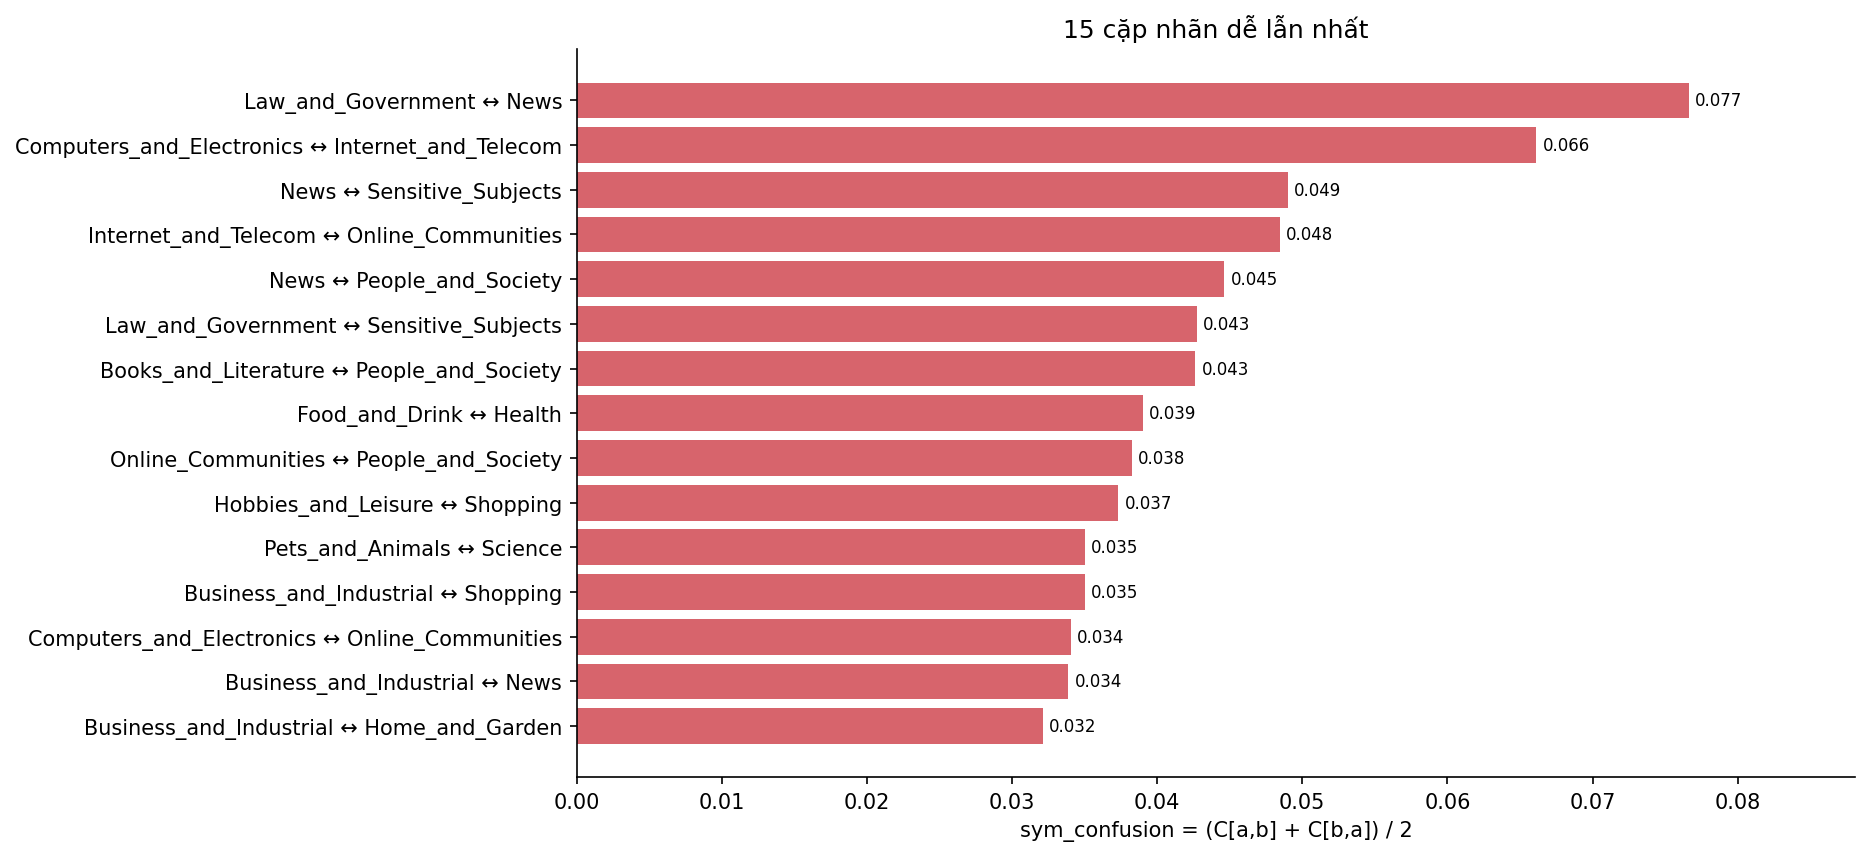

*Hình 7. Cặp Law_and_Government ↔ News đứng đầu với sym_confusion ≈ 0,077; tiếp theo là Computers_and_Electronics ↔ Internet_and_Telecom với ≈ 0,066.*

| rank | label_a | label_b | sym_confusion | top2_ambiguity | centroid_cosine |
|---|---|---|---|---|---|
| 1 | Law_and_Government | News | 0.077 | 0.067 | 0.876 |
| 2 | Computers_and_Electronics | Internet_and_Telecom | 0.066 | 0.068 | 0.869 |
| 3 | News | Sensitive_Subjects | 0.049 | 0.043 | 0.808 |
| 4 | Internet_and_Telecom | Online_Communities | 0.048 | 0.030 | 0.748 |
| 5 | News | People_and_Society | 0.045 | 0.039 | 0.794 |
| 6 | Law_and_Government | Sensitive_Subjects | 0.043 | 0.041 | 0.797 |
| 7 | Books_and_Literature | People_and_Society | 0.043 | 0.040 | 0.827 |
| 8 | Food_and_Drink | Health | 0.039 | 0.028 | 0.685 |
| 9 | Online_Communities | People_and_Society | 0.038 | 0.022 | 0.784 |
| 10 | Hobbies_and_Leisure | Shopping | 0.037 | 0.030 | 0.730 |
| 11 | Pets_and_Animals | Science | 0.035 | 0.027 | 0.712 |
| 12 | Business_and_Industrial | Shopping | 0.035 | 0.030 | 0.757 |
| 13 | Computers_and_Electronics | Online_Communities | 0.034 | 0.018 | 0.721 |
| 14 | Business_and_Industrial | News | 0.034 | 0.024 | 0.792 |
| 15 | Business_and_Industrial | Home_and_Garden | 0.032 | 0.036 | 0.739 |

### 4.4. Cây gom nhóm nhãn

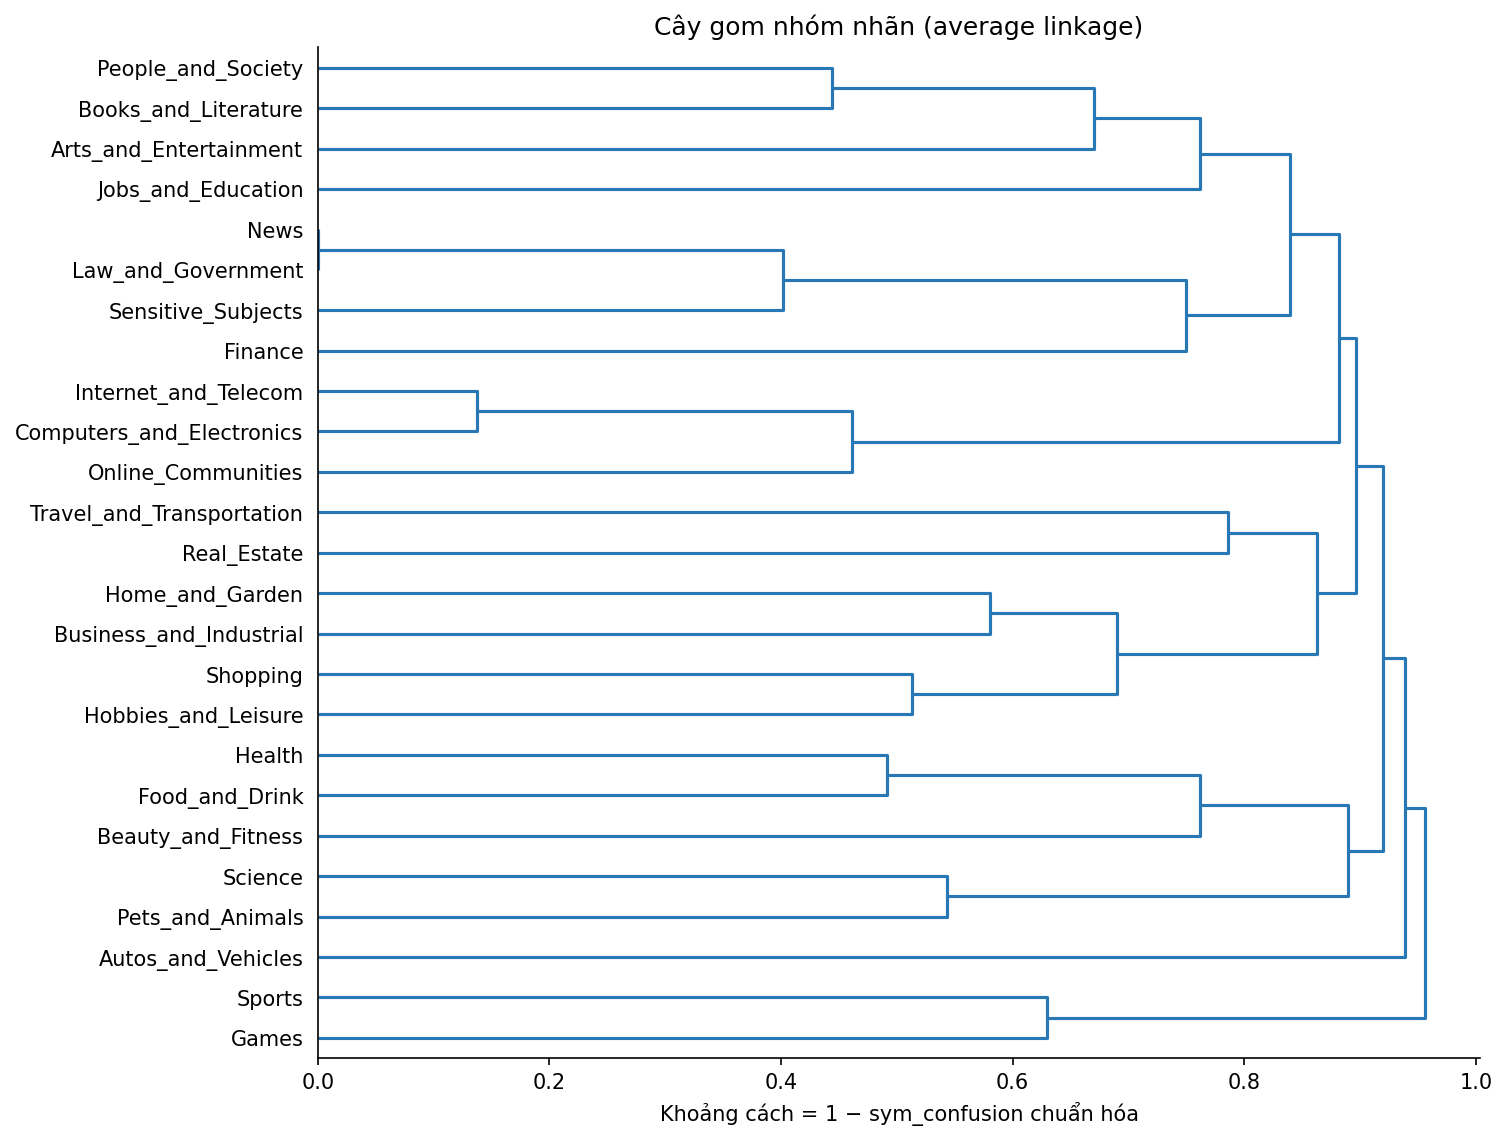

*Hình 8. Cây dùng average linkage, khoảng cách = 1 − sym_confusion / max(sym_confusion). Hai nhãn nối ở khoảng cách nhỏ có độ lẫn đối xứng cao hơn; đây không phải hệ phân loại chủ đề đã được xác nhận.*

### 4.5. F1 và số bài của từng nhãn

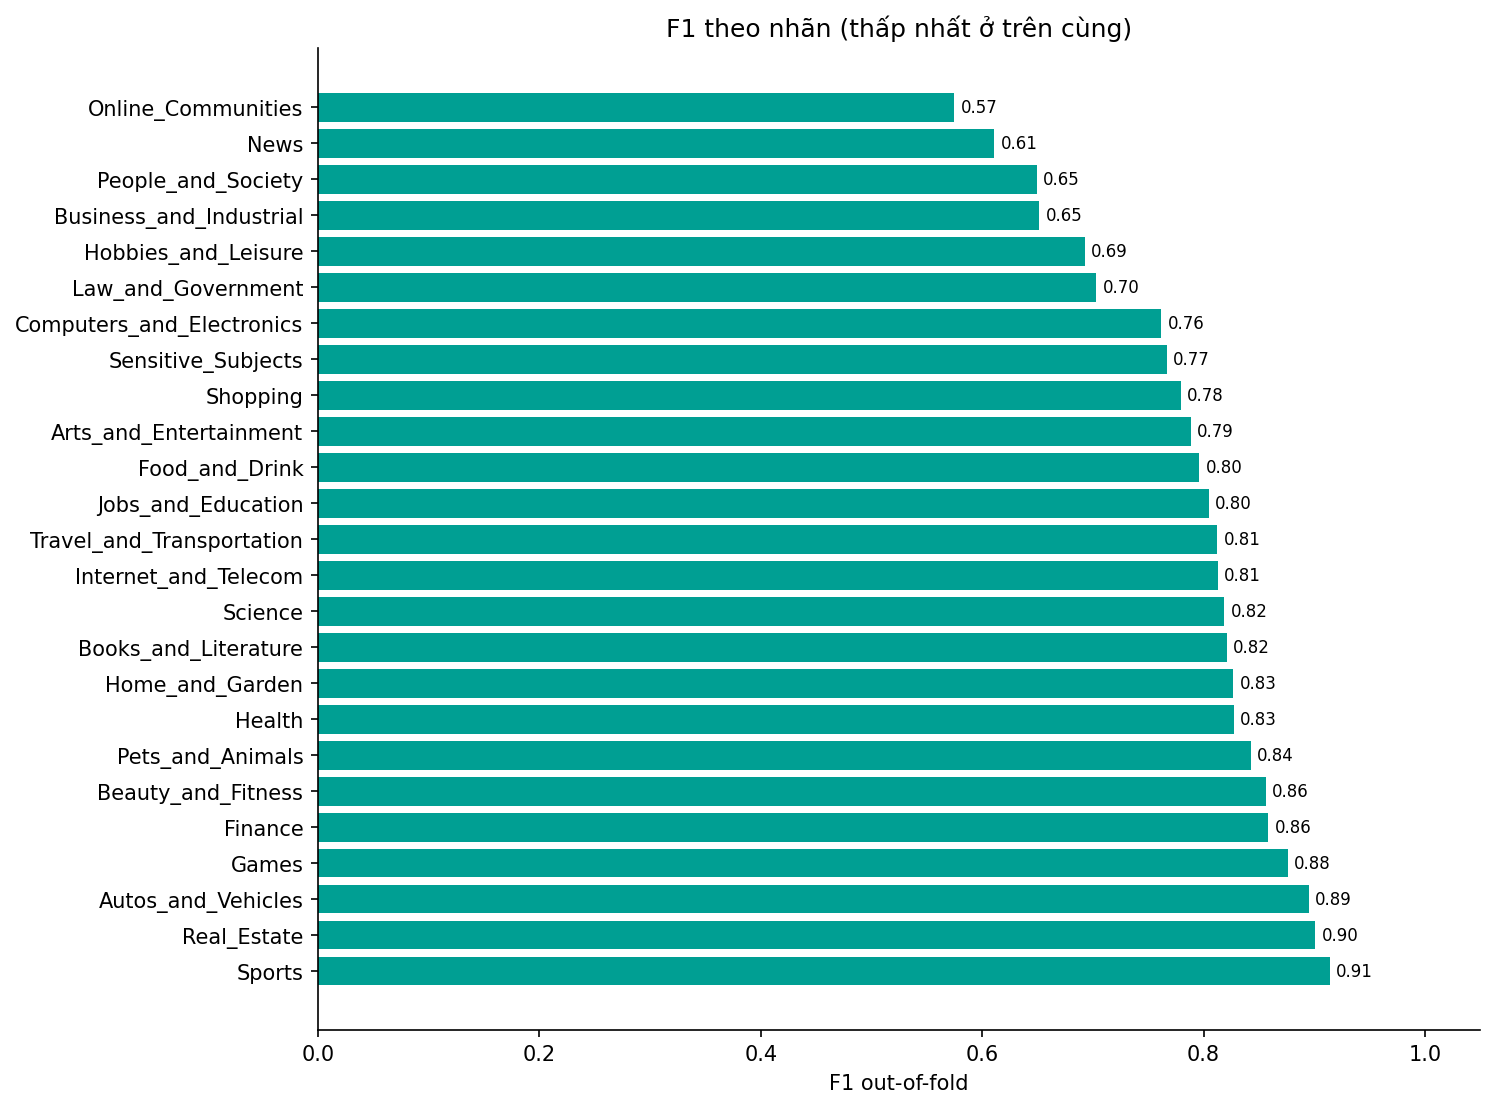

*Hình 9. Online_Communities có F1 thấp nhất (0,575); Sports cao nhất (0,914). Support trong bảng là số bài trong tập phân tích, không phải số bài của nguồn.*

| label | precision | recall | f1 | support |
|---|---|---|---|---|
| Online_Communities | 0.610 | 0.543 | 0.575 | 1313 |
| News | 0.625 | 0.598 | 0.611 | 4000 |
| People_and_Society | 0.620 | 0.682 | 0.649 | 4000 |
| Business_and_Industrial | 0.653 | 0.650 | 0.652 | 4000 |
| Hobbies_and_Leisure | 0.723 | 0.665 | 0.693 | 2440 |
| Law_and_Government | 0.696 | 0.710 | 0.703 | 4000 |
| Computers_and_Electronics | 0.745 | 0.779 | 0.762 | 4000 |
| Sensitive_Subjects | 0.765 | 0.769 | 0.767 | 4000 |
| Shopping | 0.758 | 0.803 | 0.780 | 4000 |
| Arts_and_Entertainment | 0.791 | 0.786 | 0.789 | 4000 |
| Food_and_Drink | 0.814 | 0.779 | 0.796 | 4000 |
| Jobs_and_Education | 0.794 | 0.816 | 0.805 | 4000 |
| Travel_and_Transportation | 0.811 | 0.814 | 0.812 | 4000 |
| Internet_and_Telecom | 0.815 | 0.810 | 0.813 | 4000 |
| Science | 0.807 | 0.831 | 0.819 | 4000 |
| Books_and_Literature | 0.780 | 0.867 | 0.821 | 4000 |
| Home_and_Garden | 0.798 | 0.858 | 0.827 | 4000 |
| Health | 0.844 | 0.811 | 0.827 | 4000 |
| Pets_and_Animals | 0.856 | 0.830 | 0.843 | 4000 |
| Beauty_and_Fitness | 0.883 | 0.832 | 0.856 | 4000 |
| Finance | 0.874 | 0.844 | 0.858 | 4000 |
| Games | 0.915 | 0.841 | 0.876 | 4000 |
| Autos_and_Vehicles | 0.906 | 0.884 | 0.895 | 4000 |
| Real_Estate | 0.899 | 0.903 | 0.901 | 4000 |
| Sports | 0.927 | 0.901 | 0.914 | 4000 |

### 4.6. Độ nhạy khi chỉ đọc đầu bài

| Giới hạn văn bản | Macro-F1 | Accuracy |
|---|---:|---:|
| 1.000 ký tự đầu | 0,7834 | 0,7899 |
| Tối đa 5.000 ký tự | 0,7857 | 0,7929 |

Chênh lệch Macro-F1 khoảng **0,0023** trong lần chạy này. Đây là so sánh giới hạn ký tự của mô hình khảo sát;
chưa đủ để kết luận mọi bài chỉ cần đọc phần đầu, hoặc quy đổi sang giới hạn token của bộ gán nhãn gốc.

<a id="nghi-van"></a>

## 5. Những trường hợp cần kiểm tra nhãn bằng tay

Một bài được gắn cờ khi nhãn dự đoán khác nhãn nguồn và xác suất dự đoán cao nhất **≥ 0,7**.
Có **2.978 / 95.753 bài (3,11%)** được gắn cờ trong tập phân tích.
Đây là bất đồng tự tin của mô hình, chưa phải tỉ lệ nhãn sai đã được xác nhận; xác suất này cũng chưa được bảo đảm là đã hiệu chuẩn.

**News** có tỉ lệ bị gắn cờ cao nhất: **272 / 4.000 bài (6,8%)**.
Các tỉ lệ trong bảng nằm trên thang 0–1 và có mẫu số là số bài của từng nhãn trong tập phân tích.

| label | n | n_confident_mismatch | confident_mismatch_rate | most_often_read_as | most_often_read_as_share | mean_prob_of_given_label |
|---|---|---|---|---|---|---|
| News | 4000 | 272 | 0.068 | Law_and_Government | 0.19 | 0.421 |
| Online_Communities | 1313 | 63 | 0.048 | Games | 0.21 | 0.310 |
| Business_and_Industrial | 4000 | 172 | 0.043 | Home_and_Garden | 0.15 | 0.434 |
| Computers_and_Electronics | 4000 | 164 | 0.041 | Internet_and_Telecom | 0.31 | 0.569 |
| Food_and_Drink | 4000 | 162 | 0.041 | Health | 0.27 | 0.609 |
| Sensitive_Subjects | 4000 | 156 | 0.039 | Books_and_Literature | 0.24 | 0.582 |
| Law_and_Government | 4000 | 152 | 0.038 | News | 0.24 | 0.504 |
| Pets_and_Animals | 4000 | 151 | 0.038 | Science | 0.34 | 0.678 |
| Hobbies_and_Leisure | 2440 | 87 | 0.036 | Pets_and_Animals | 0.20 | 0.434 |
| People_and_Society | 4000 | 139 | 0.035 | Books_and_Literature | 0.22 | 0.437 |
| Health | 4000 | 136 | 0.034 | Food_and_Drink | 0.33 | 0.668 |
| Beauty_and_Fitness | 4000 | 124 | 0.031 | Shopping | 0.26 | 0.686 |
| Travel_and_Transportation | 4000 | 123 | 0.031 | Real_Estate | 0.24 | 0.661 |
| Games | 4000 | 121 | 0.030 | Sports | 0.50 | 0.728 |
| Arts_and_Entertainment | 4000 | 114 | 0.029 | Books_and_Literature | 0.32 | 0.594 |
| Shopping | 4000 | 110 | 0.028 | Home_and_Garden | 0.14 | 0.595 |
| Science | 4000 | 103 | 0.026 | Pets_and_Animals | 0.41 | 0.636 |
| Internet_and_Telecom | 4000 | 102 | 0.025 | Computers_and_Electronics | 0.33 | 0.637 |
| Finance | 4000 | 99 | 0.025 | Law_and_Government | 0.19 | 0.703 |
| Jobs_and_Education | 4000 | 95 | 0.024 | Books_and_Literature | 0.20 | 0.649 |
| Real_Estate | 4000 | 82 | 0.021 | Home_and_Garden | 0.34 | 0.793 |
| Home_and_Garden | 4000 | 71 | 0.018 | Shopping | 0.21 | 0.646 |
| Books_and_Literature | 4000 | 68 | 0.017 | People_and_Society | 0.40 | 0.663 |
| Sports | 4000 | 62 | 0.015 | Games | 0.39 | 0.791 |
| Autos_and_Vehicles | 4000 | 50 | 0.013 | Home_and_Garden | 0.16 | 0.764 |

**Cách đọc bảng:** `most_often_read_as` là nhãn dự đoán nhầm phổ biến nhất;
`most_often_read_as_share` là tỉ trọng của nhãn dự đoán đó trong các bài bị gắn cờ của nhãn đang xét (đã đạt ngưỡng 0,7).
`mean_prob_of_given_label` là xác suất trung bình mô hình gán cho nhãn nguồn trên toàn bộ bài của nhãn đó.

Bộ kiểm tra tay đã được tạo gồm **480 bài** (phần A: 300, B: 150, C: 30).
Nội dung bài và danh sách từng ID được giữ trong bộ kết quả nội bộ; báo cáo chỉ trình bày số liệu tổng hợp.

<a id="kich-ban"></a>

## 6. Kịch bản gộp hoặc bỏ nhãn: ước lượng từ dự đoán đã có

**Cách tính:** ánh xạ lại nhãn và dự đoán cũ để tính lại chỉ số, không huấn luyện lại mô hình.
S0 là cấu hình 25 nhãn ban đầu; S1 gộp từng cặp riêng lẻ; S2 gộp tuần tự.
Với S3, các bài có nhãn nguồn bị bỏ được loại khỏi phép tính; với bài còn lại mà dự đoán top-1 là nhãn bị bỏ, dùng dự đoán top-2 thay thế.
Các kịch bản làm thay đổi bài toán đánh giá nên điểm số giữa chúng cần được đọc cùng số nhãn và phạm vi bị ảnh hưởng.

### 6.1. Gộp tuần tự (S2)

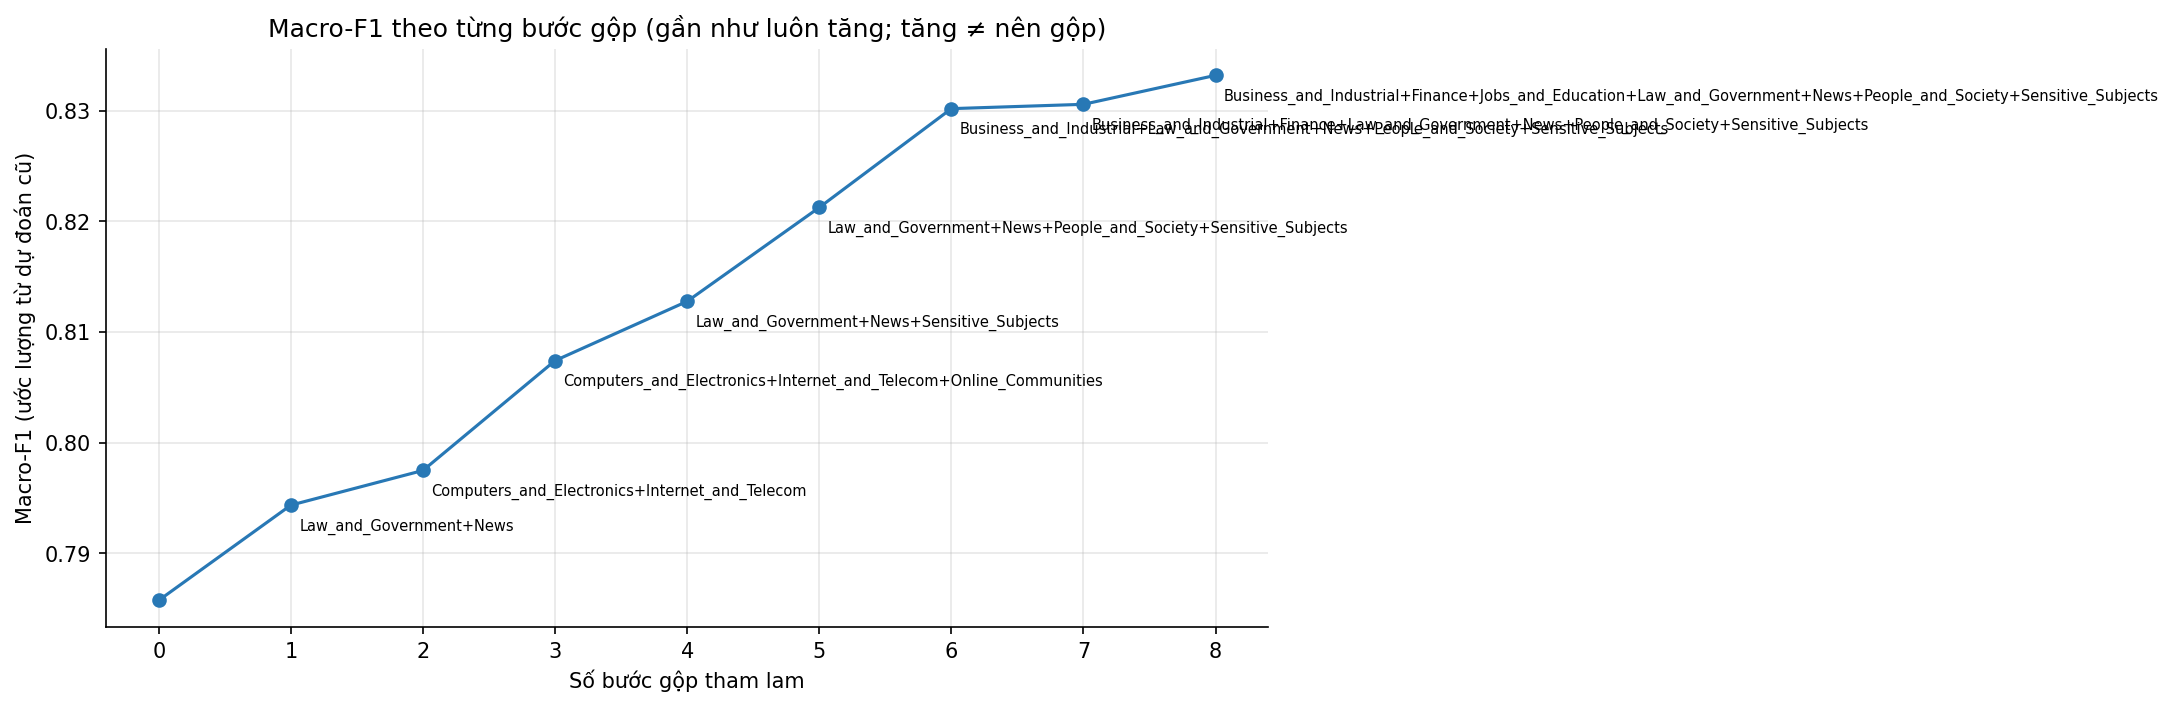

*Hình 10. Đường cong tính lại từ dự đoán cũ: Macro-F1 từ khoảng 0,786 với 25 nhãn lên 0,833 với 17 nhãn. Điểm tăng trên bài toán ít nhãn hơn chưa phải bằng chứng nên gộp.*

Nhãn gộp được ghi trên hình; bảng dưới giữ các chỉ số để đối chiếu.

**S0 và S2 — điểm xuất phát và các bước gộp tuần tự**

| Kịch bản | Số nhãn | Macro-F1 | Accuracy | Δ Macro-F1 |
|---|---|---|---|---|
| S0 | 25 | 0.786 | 0.793 | +0.000 |
| S2: bước 1 | 24 | 0.794 | 0.799 | +0.009 |
| S2: bước 2 | 23 | 0.797 | 0.805 | +0.012 |
| S2: bước 3 | 22 | 0.807 | 0.808 | +0.022 |
| S2: bước 4 | 21 | 0.813 | 0.816 | +0.027 |
| S2: bước 5 | 20 | 0.821 | 0.824 | +0.036 |
| S2: bước 6 | 19 | 0.830 | 0.830 | +0.044 |
| S2: bước 7 | 18 | 0.831 | 0.837 | +0.045 |
| S2: bước 8 | 17 | 0.833 | 0.845 | +0.047 |

**F1 thấp nhất và phạm vi bị ảnh hưởng:**

| Kịch bản | Nhãn có F1 thấp nhất | F1 thấp nhất | % tập phân tích | % toàn nguồn |
|---|---|---|---|---|
| S0 | Online_Communities | 0.575 | 0.0 | 0.00 |
| S2: bước 1 | Online_Communities | 0.575 | 8.4 | 9.27 |
| S2: bước 2 | Online_Communities | 0.575 | 16.7 | 16.63 |
| S2: bước 3 | People_and_Society | 0.649 | 18.1 | 17.06 |
| S2: bước 4 | People_and_Society | 0.649 | 22.3 | 23.17 |
| S2: bước 5 | Business_and_Industrial | 0.652 | 26.4 | 30.11 |
| S2: bước 6 | Hobbies_and_Leisure | 0.693 | 30.6 | 35.24 |
| S2: bước 7 | Hobbies_and_Leisure | 0.693 | 34.8 | 37.74 |
| S2: bước 8 | Hobbies_and_Leisure | 0.693 | 39.0 | 42.38 |

### 6.2. S1 — gộp từng cặp riêng lẻ

| Kịch bản | Số nhãn | Macro-F1 | Accuracy | Δ Macro-F1 |
|---|---|---|---|---|
| S1: Law_and_Government+News | 24 | 0.794 | 0.799 | +0.009 |
| S1: Computers_and_Electronics+Internet_and_Telecom | 24 | 0.788 | 0.798 | +0.003 |
| S1: News+Sensitive_Subjects | 24 | 0.792 | 0.797 | +0.006 |
| S1: Internet_and_Telecom+Online_Communities | 24 | 0.794 | 0.795 | +0.008 |
| S1: News+People_and_Society | 24 | 0.794 | 0.797 | +0.008 |
| S1: Law_and_Government+Sensitive_Subjects | 24 | 0.790 | 0.797 | +0.004 |
| S1: Books_and_Literature+People_and_Society | 24 | 0.790 | 0.796 | +0.004 |
| S1: Food_and_Drink+Health | 24 | 0.786 | 0.796 | +0.001 |
| S1: Online_Communities+People_and_Society | 24 | 0.795 | 0.794 | +0.009 |
| S1: Hobbies_and_Leisure+Shopping | 24 | 0.790 | 0.795 | +0.004 |
| S1: Pets_and_Animals+Science | 24 | 0.785 | 0.796 | -0.000 |
| S1: Business_and_Industrial+Shopping | 24 | 0.790 | 0.796 | +0.004 |
| S1: Computers_and_Electronics+Online_Communities | 24 | 0.794 | 0.794 | +0.008 |
| S1: Business_and_Industrial+News | 24 | 0.794 | 0.796 | +0.008 |
| S1: Business_and_Industrial+Home_and_Garden | 24 | 0.789 | 0.796 | +0.003 |

**F1 thấp nhất và phạm vi bị ảnh hưởng:**

| Kịch bản | Nhãn có F1 thấp nhất | F1 thấp nhất | % tập phân tích | % toàn nguồn |
|---|---|---|---|---|
| S1: Law_and_Government+News | Online_Communities | 0.575 | 8.4 | 9.27 |
| S1: Computers_and_Electronics+Internet_and_Telecom | Online_Communities | 0.575 | 8.4 | 7.37 |
| S1: News+Sensitive_Subjects | Online_Communities | 0.575 | 8.4 | 12.43 |
| S1: Internet_and_Telecom+Online_Communities | News | 0.611 | 5.5 | 3.55 |
| S1: News+People_and_Society | Online_Communities | 0.575 | 8.4 | 13.26 |
| S1: Law_and_Government+Sensitive_Subjects | Online_Communities | 0.575 | 8.4 | 9.05 |
| S1: Books_and_Literature+People_and_Society | Online_Communities | 0.575 | 8.4 | 10.19 |
| S1: Food_and_Drink+Health | Online_Communities | 0.575 | 8.4 | 12.84 |
| S1: Online_Communities+People_and_Society | News | 0.611 | 5.5 | 7.36 |
| S1: Hobbies_and_Leisure+Shopping | Online_Communities | 0.575 | 6.7 | 2.35 |
| S1: Pets_and_Animals+Science | Online_Communities | 0.575 | 8.4 | 3.05 |
| S1: Business_and_Industrial+Shopping | Online_Communities | 0.575 | 8.4 | 6.68 |
| S1: Computers_and_Electronics+Online_Communities | News | 0.611 | 5.5 | 4.67 |
| S1: Business_and_Industrial+News | Online_Communities | 0.575 | 8.4 | 11.46 |
| S1: Business_and_Industrial+Home_and_Garden | Online_Communities | 0.575 | 8.4 | 9.49 |

### 6.3. S3 — bỏ từng nhãn khỏi phép tính

| Kịch bản | Số nhãn | Macro-F1 | Accuracy | Δ Macro-F1 |
|---|---|---|---|---|
| S3: bỏ Online_Communities | 24 | 0.797 | 0.799 | +0.012 |
| S3: bỏ News | 24 | 0.802 | 0.810 | +0.016 |
| S3: bỏ People_and_Society | 24 | 0.800 | 0.807 | +0.014 |
| S3: bỏ Business_and_Industrial | 24 | 0.799 | 0.807 | +0.013 |
| S3: bỏ Hobbies_and_Leisure | 24 | 0.794 | 0.800 | +0.008 |
| S3: bỏ Sensitive_Subjects | 24 | 0.792 | 0.800 | +0.006 |

**F1 thấp nhất và phạm vi bị ảnh hưởng:**

| Kịch bản | Nhãn có F1 thấp nhất | F1 thấp nhất | % tập phân tích | % toàn nguồn |
|---|---|---|---|---|
| S3: bỏ Online_Communities | News | 0.613 | 1.4 | 0.43 |
| S3: bỏ News | Online_Communities | 0.579 | 4.2 | 6.32 |
| S3: bỏ People_and_Society | Online_Communities | 0.594 | 4.2 | 6.93 |
| S3: bỏ Business_and_Industrial | Online_Communities | 0.579 | 4.2 | 5.14 |
| S3: bỏ Hobbies_and_Leisure | Online_Communities | 0.582 | 2.5 | 0.81 |
| S3: bỏ Sensitive_Subjects | Online_Communities | 0.578 | 4.2 | 6.11 |

`Δ Macro-F1` là chênh lệch so với S0, tính trên giá trị chưa làm tròn nên có thể khác phép trừ các số hiển thị.
Hai cột phần trăm lần lượt là tỉ trọng bài thuộc các nhãn bị tác động trong tập phân tích đã giới hạn mỗi lớp và trong toàn bộ nguồn.

- Gộp nhãn làm thay đổi độ khó và cách tính điểm; không diễn giải mức tăng thành cải thiện mô hình trên cùng một bài toán.
- Bỏ nhãn khỏi phép tính làm mất khả năng đánh giá loại bài đó, trong khi loại bài ấy vẫn tồn tại ngoài thực tế.
- Kết quả chính thức của một cấu hình nhãn mới cần huấn luyện và đánh giá lại theo quy trình phù hợp.

<a id="gioi-han"></a>

## 7. Giới hạn khi diễn giải kết quả

Không phát hiện trùng văn bản khác nhãn trong mẫu 300k không có nghĩa toàn bộ 12,17 triệu bài không có hiện tượng này.

- Nhãn `domain` do máy gán (nvidia/domain-classifier), chưa có người kiểm duyệt; mọi 'nghi gán sai' chỉ là nghi vấn.
- Mô hình phân tích (TF-IDF + Logistic Regression, out-of-fold) là công cụ đo, không phải mô hình chính thức; không so trực tiếp với baseline Gold.
- Mỗi nhãn được cắt tối đa `per_class_cap` bài khi train mô hình phân tích, nên các tỉ lệ bài trong tập này không phản ánh tỉ lệ ngoài đời; phần trăm 'toàn dataset' lấy từ mục 2.
- TF-IDF được fit một lần trên toàn bộ tập phân tích (không dùng nhãn) để tiết kiệm thời gian; bộ phân loại thì luôn dự đoán bài chưa từng thấy.
- Chuẩn hóa văn bản chỉ ở mức Silver V1 (NFC, khoảng trắng); KHÔNG áp dụng làm sạch Silver V2 (quảng cáo, điều hướng...), nên nhiễu crawl có thể làm tăng độ lẫn.
- Văn bản dài bị cắt (`text_char_limit` ký tự) khi đưa vào TF-IDF; bộ gán nhãn gốc chỉ đọc ~512 token đầu.
- Mẫu khảo sát là mẫu ngẫu nhiên các row group rồi lấy ngẫu nhiên dòng trong mỗi row group; nếu các bài gần nhau trong một row group giống nhau thì kích thước mẫu hiệu dụng nhỏ hơn số dòng.
- Số liệu kịch bản gộp/bỏ nhãn tính lại từ dự đoán cũ (không train lại) nên chỉ là ước lượng nhanh.
- Dataset chưa rõ license; không đưa văn bản bài viết vào báo cáo hoặc Git.

<a id="lan-chay"></a>

## 8. Thông tin lần chạy và cách chia sẻ

| Thông tin | Giá trị |
|---|---|
| Run ID | `survey_b81fcce5_seed42_n300000_69445d1c` |
| Dataset | `VTSNLP/vietnamese_curated_dataset` |
| Revision dataset | `b81fcce58945970117a1b56d50ec81be2628a5c3` |
| Commit code ghi nhận khi chạy | `77252135ee9620f143c1c49ce6a4d395abad53c3` |
| Bronze manifest | `source_manifest_b81fcce589_seed42_buf10000_n50000.json` |
| Seed / số fold | 42 / 5 |
| Tiền xử lý | Chuẩn hóa tối thiểu mức Silver V1; chưa áp dụng làm sạch Silver V2 |
| Mô hình khảo sát | TF-IDF word 1–2 gram, min_df = 2, tối đa 100.000 đặc trưng; Logistic Regression, max_iter = 300 |
| Python ghi nhận | 3.13.18 |
| scikit-learn / pandas / NumPy ghi nhận | 1.6.1 / 2.2.3 / 2.4.6 |

**Bản chia sẻ:** notebook `notebooks/reports/label_survey_b81fcce5_seed42_n300000.ipynb`
chứa bảng tổng hợp và 10 biểu đồ nhúng sẵn. Mở xem trực tiếp, không cần chạy lại hay truy cập CSV, Drive hoặc dataset.

**Bộ kết quả đầy đủ:** giữ tại `data/04_reports/survey_b81fcce5_seed42_n300000_69445d1c/` trên máy hoặc trong kho lưu trữ chung của nhóm.
CSV, ZIP và nội dung audit không cần đưa lên Git để đọc báo cáo này.
Markdown trong bộ local dùng đường dẫn ảnh tương đối; khi chia sẻ riêng Markdown phải kèm các PNG cùng thư mục.